# 🏦 Bank Customer Churn: Modelling & Evaluation

This notebook trains and evaluates the churn model used in the Streamlit app.

**Steps**
1. Load the processed dataset
2. Define features and split the data
3. Baseline: Logistic Regression
4. Random Forest: training and cross-validation
5. Evaluate the deployed model (`models/`)
6. Model comparison
7. ROC curves
8. Feature importance
9. Decision threshold and confusion matrix
10. Prediction function for new customers

## 1. Setup & Load Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
                             precision_recall_curve, confusion_matrix, classification_report)

# Works whether the notebook is run from the repo root or from /notebooks
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "Bank_Churn_Final_With_NumericClusters.csv"
MODEL_DIR = ROOT / "models"

df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Churn rate: {df['Exited'].mean():.1%}")
df.head()

Rows: 10,000 | Columns: 21
Churn rate: 20.4%


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,...,EstimatedSalary,Exited,ProductPerYear,balance_to_income,income_v_product,Gender_num,France,Germany,Spain,Cluster_Num
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,...,101348.88,1,0.500,0.000000,50674.440000,1,1,0,0,3
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,...,112542.58,0,1.000,0.744670,56271.290000,1,0,0,1,1
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,...,113931.57,1,0.375,1.401362,28482.892500,1,1,0,0,3
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,...,93826.63,0,2.000,0.000000,31275.543333,1,1,0,0,1
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,...,79084.10,0,0.500,1.587035,39542.050000,1,0,0,1,2


## 2. Features & Train/Test Split

The model uses 9 original fields plus 3 engineered ratios:

| Feature | Formula | Meaning |
|---|---|---|
| `ProductPerYear` | `NumOfProducts / (Tenure + 0.1)` | Engagement depth over time |
| `balance_to_income` | `Balance / (EstimatedSalary + 1)` | Share of wealth held at the bank |
| `income_v_product` | `EstimatedSalary / (NumOfProducts + 1)` | Cross-sell potential |

In [2]:
FEATURES = [
    'CreditScore', 'Gender_num', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
    'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
    'ProductPerYear', 'balance_to_income', 'income_v_product'
]
TARGET = 'Exited'

X = df[FEATURES]
y = df[TARGET]

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(f"Train rows: {len(x_train):,} | Test rows: {len(x_test):,}")
print(f"Churn rate — train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Train rows: 8,000 | Test rows: 2,000
Churn rate — train: 20.4% | test: 20.3%


## 3. Baseline: Logistic Regression

In [3]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(x_train_scaled, y_train)

lr_proba = lr.predict_proba(x_test_scaled)[:, 1]
lr_auc = roc_auc_score(y_test, lr_proba)
lr_acc = accuracy_score(y_test, lr_proba >= 0.5)

print(f"Logistic Regression — Test ROC-AUC: {lr_auc:.4f}")
print(f"Logistic Regression — Accuracy:     {lr_acc:.2%}")

Logistic Regression — Test ROC-AUC: 0.7814
Logistic Regression — Accuracy:     81.25%


## 4. Random Forest: Training & Cross-Validation

Hyperparameters are set to limit overfitting: shallow trees, large leaves and balanced class weights.

In [4]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=25,
    min_samples_split=40,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf, x_train_scaled, y_train, cv=cv, scoring="roc_auc")

print("5-fold CV ROC-AUC per fold:", np.round(cv_scores, 4))
print(f"Mean CV ROC-AUC: {cv_scores.mean():.4f} (± {cv_scores.std():.4f})")

5-fold CV ROC-AUC per fold: [0.8453 0.8517 0.8547 0.8195 0.8355]
Mean CV ROC-AUC: 0.8414 (± 0.0127)


## 5. Evaluate the Deployed Model

The Streamlit app loads the trained model, scaler and decision threshold from `models/`. They are evaluated here on the same hold-out test set.

In [5]:
model = joblib.load(MODEL_DIR / "churn_model.pkl")
deployed_scaler = joblib.load(MODEL_DIR / "scaler.pkl")
best_threshold = float(joblib.load(MODEL_DIR / "threshold.pkl"))

train_proba = model.predict_proba(deployed_scaler.transform(x_train))[:, 1]
rf_proba = model.predict_proba(deployed_scaler.transform(x_test))[:, 1]

train_auc = roc_auc_score(y_train, train_proba)
rf_auc = roc_auc_score(y_test, rf_proba)
rf_acc = accuracy_score(y_test, rf_proba >= best_threshold)

print(f"Random Forest — Test ROC-AUC:  {rf_auc:.4f}")
print(f"Random Forest — Train ROC-AUC: {train_auc:.4f}")
print(f"Overfitting gap (train − test): {train_auc - rf_auc:.4f}",
      "✅ good generalisation" if train_auc - rf_auc < 0.05 else "⚠️ possible overfitting")
print(f"Decision threshold: {best_threshold:.3f}")
print(f"Random Forest — Accuracy at threshold: {rf_acc:.2%}")

Random Forest — Test ROC-AUC:  0.8483
Random Forest — Train ROC-AUC: 0.8881
Overfitting gap (train − test): 0.0398 ✅ good generalisation
Decision threshold: 0.579
Random Forest — Accuracy at threshold: 83.85%


## 6. Model Comparison

In [6]:
comparison = pd.DataFrame({
    "Logistic Regression (Baseline)": [round(lr_auc, 4), "—", f"{lr_acc:.2%}"],
    "Random Forest (Deployed)": [round(rf_auc, 4), round(cv_scores.mean(), 4), f"{rf_acc:.2%}"],
}, index=["ROC-AUC (test)", "ROC-AUC (5-fold CV)", "Accuracy"])

print(f"AUC improvement over baseline: +{(rf_auc - lr_auc) / lr_auc:.1%}")
comparison

AUC improvement over baseline: +8.6%


,Logistic Regression (Baseline),Random Forest (Deployed)
ROC-AUC (test),0.7814,0.8483
ROC-AUC (5-fold CV),—,0.8414
Accuracy,81.25%,83.85%


## 7. ROC Curves

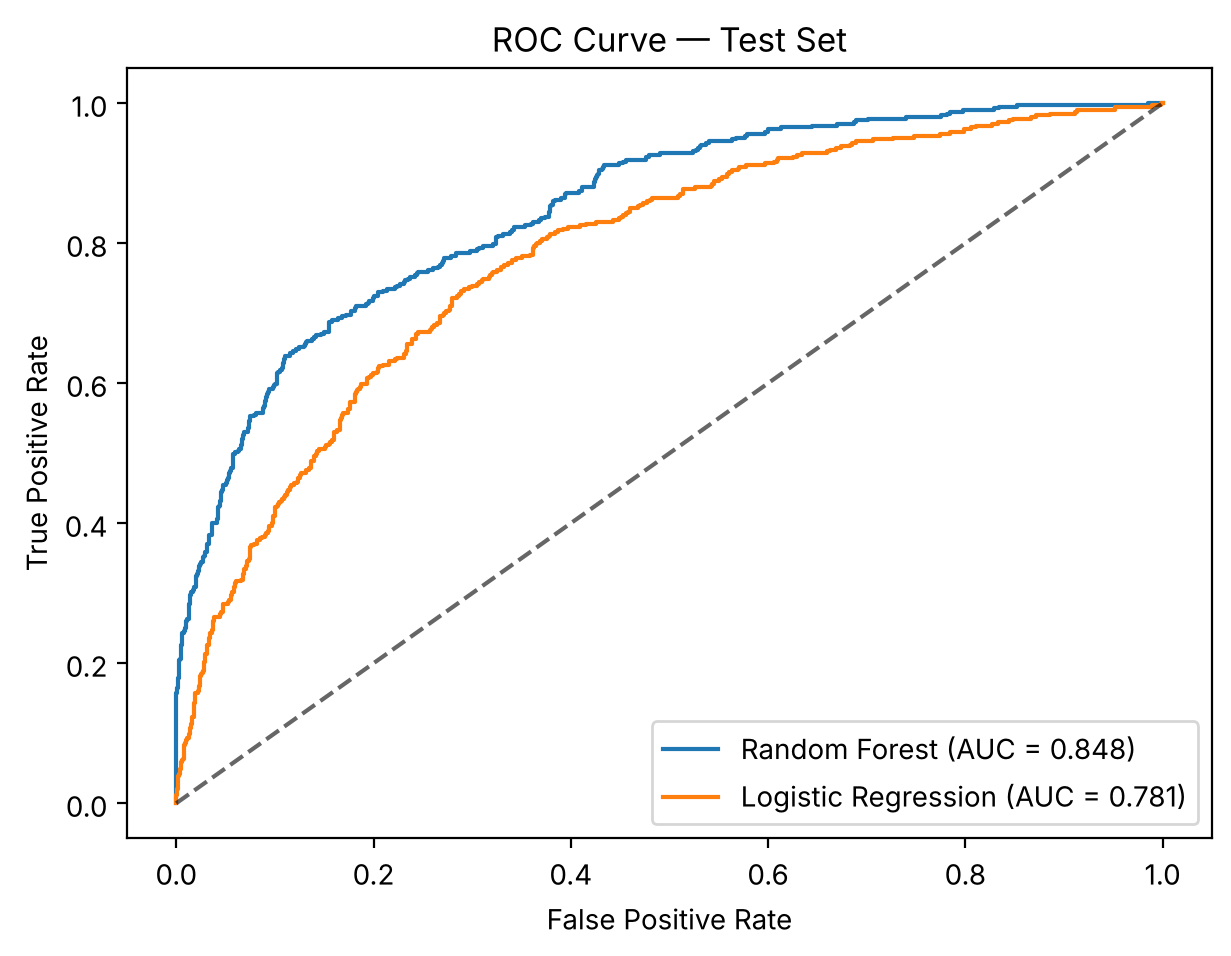

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, proba, auc in [("Random Forest", rf_proba, rf_auc), ("Logistic Regression", lr_proba, lr_auc)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.6)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Test Set")
ax.legend()
plt.show()

## 8. Feature Importance

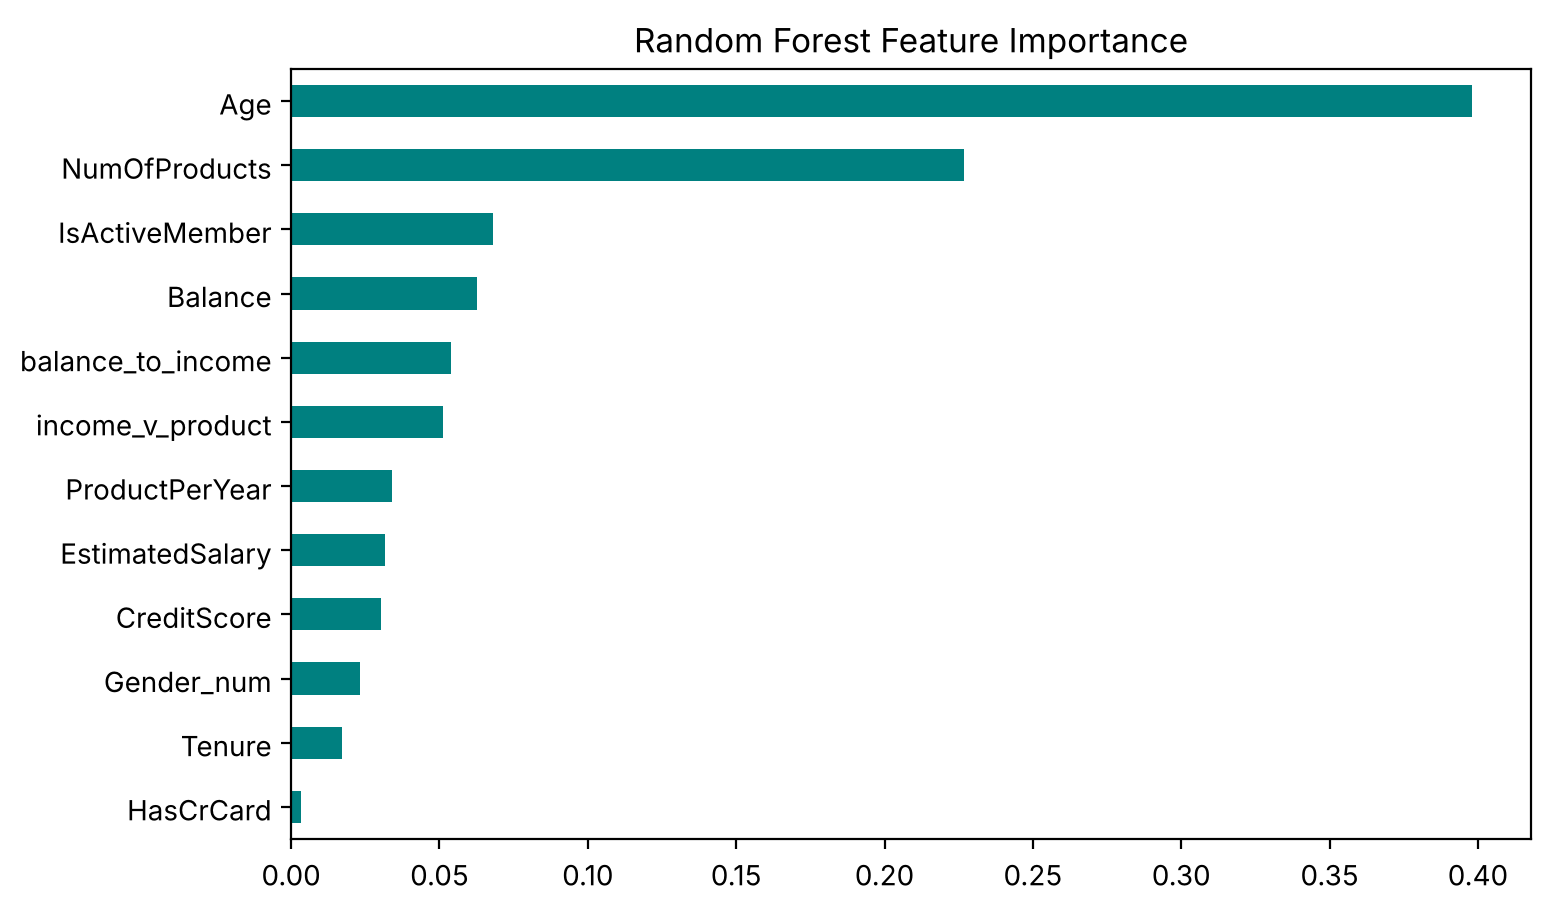

,Importance
Age,0.398
NumOfProducts,0.227
IsActiveMember,0.068
Balance,0.063
balance_to_income,0.054
income_v_product,0.051
ProductPerYear,0.034
EstimatedSalary,0.032
CreditScore,0.030
Gender_num,0.023


In [8]:
feat_imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
feat_imp.plot(kind="barh", color="teal", ax=ax)
ax.set_title("Random Forest Feature Importance")
plt.show()

feat_imp.sort_values(ascending=False).round(3).to_frame("Importance")

## 9. Decision Threshold & Confusion Matrix

The threshold is chosen to maximise the F1-score instead of using the default 0.5, to balance catching churners (recall) with avoiding false alarms (precision).

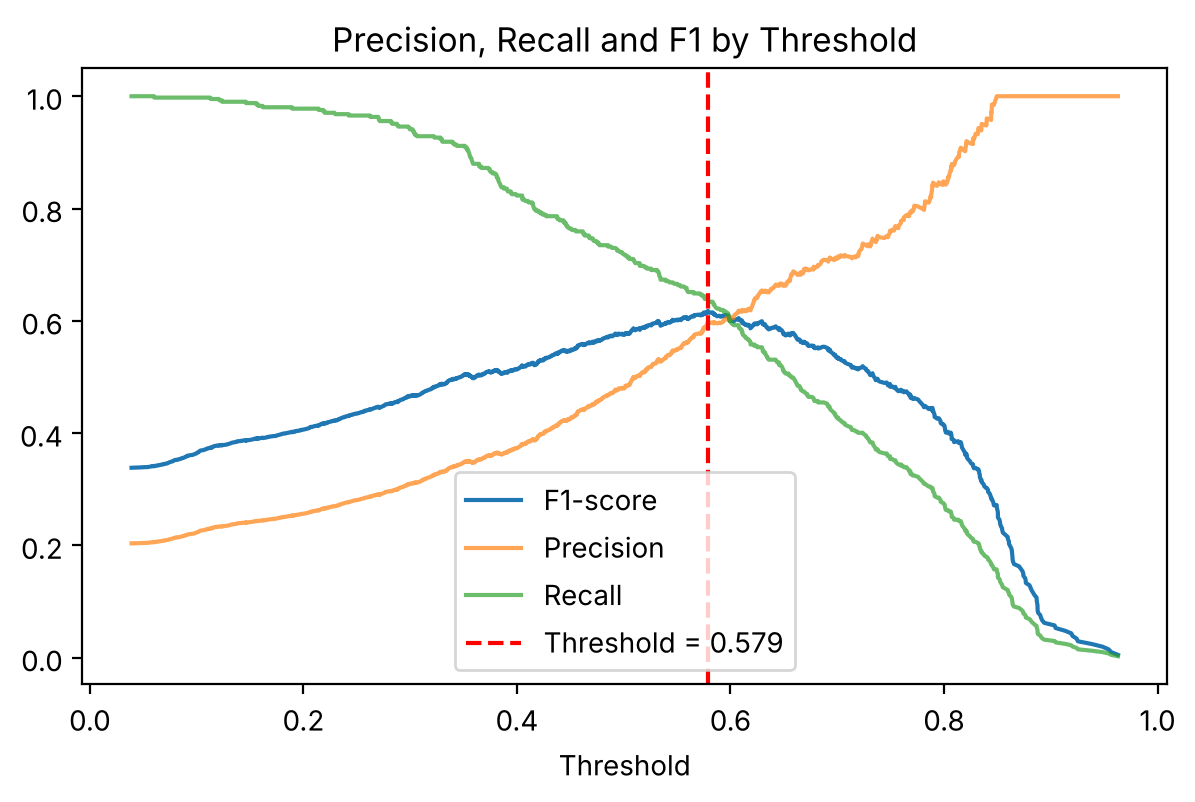

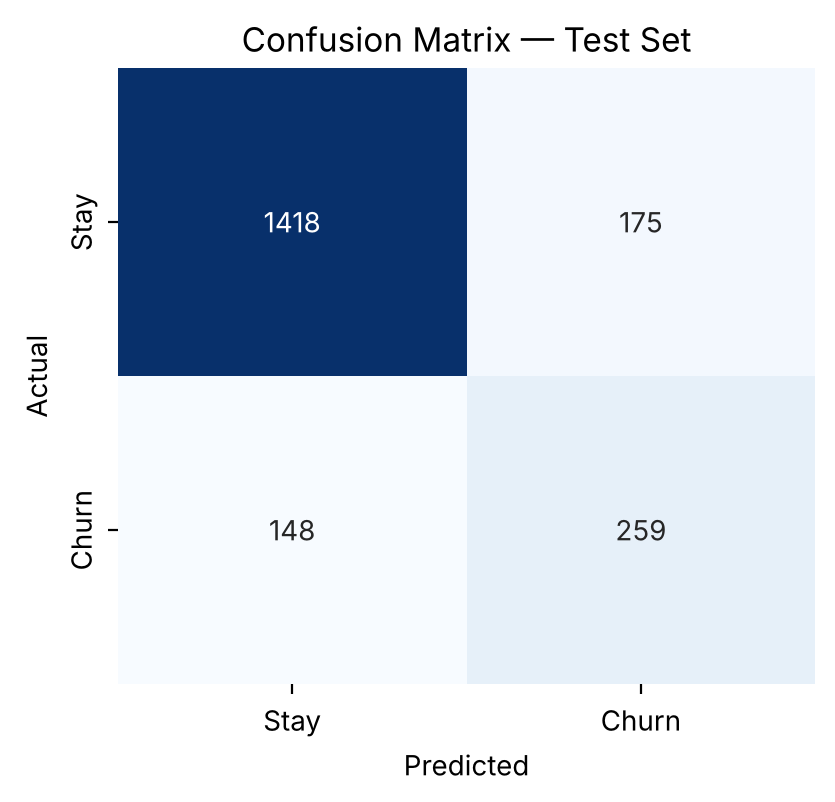

              precision    recall  f1-score   support

        Stay       0.91      0.89      0.90      1593
       Churn       0.60      0.64      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.76      0.76      2000
weighted avg       0.84      0.84      0.84      2000



In [9]:
precision, recall, thresholds = precision_recall_curve(y_test, rf_proba)
f1 = 2 * precision * recall / (precision + recall + 1e-6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, f1[:-1], label="F1-score")
ax.plot(thresholds, precision[:-1], label="Precision", alpha=0.7)
ax.plot(thresholds, recall[:-1], label="Recall", alpha=0.7)
ax.axvline(best_threshold, color="red", ls="--", label=f"Threshold = {best_threshold:.3f}")
ax.set_xlabel("Threshold")
ax.set_title("Precision, Recall and F1 by Threshold")
ax.legend()
plt.show()

y_pred = (rf_proba >= best_threshold).astype(int)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix — Test Set")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Stay", "Churn"]))

## 10. Prediction Function for New Customers

In [10]:
def get_predictions(input_df: pd.DataFrame) -> pd.Series:
    """Apply feature engineering and return churn probabilities."""
    d = input_df.copy()
    if "Gender_num" not in d.columns:
        d["Gender_num"] = np.where(d["Gender"].astype(str).str.lower().str.startswith("f"), 1, 0)
    d["ProductPerYear"] = d["NumOfProducts"] / (d["Tenure"] + 0.1)
    d["balance_to_income"] = d["Balance"] / (d["EstimatedSalary"] + 1)
    d["income_v_product"] = d["EstimatedSalary"] / (d["NumOfProducts"] + 1)
    return pd.Series(model.predict_proba(deployed_scaler.transform(d[FEATURES]))[:, 1], index=d.index)


customers = pd.DataFrame([
    {"CreditScore": 650, "Gender": "Female", "Age": 45, "Tenure": 3, "Balance": 50000,
     "NumOfProducts": 2, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 60000},
    {"CreditScore": 580, "Gender": "Female", "Age": 52, "Tenure": 2, "Balance": 120000,
     "NumOfProducts": 1, "HasCrCard": 0, "IsActiveMember": 0, "EstimatedSalary": 40000},
    {"CreditScore": 720, "Gender": "Male", "Age": 30, "Tenure": 5, "Balance": 0,
     "NumOfProducts": 2, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 70000},
])

customers["Churn Probability"] = get_predictions(customers).round(3)
customers["Verdict"] = np.where(customers["Churn Probability"] >= best_threshold, "🔴 High risk", "🟢 Low risk")
customers[["Age", "Balance", "NumOfProducts", "IsActiveMember", "Churn Probability", "Verdict"]]

,Age,Balance,NumOfProducts,IsActiveMember,Churn Probability,Verdict
0,45,50000,2,1,0.480,🟢 Low risk
1,52,120000,1,0,0.878,🔴 High risk
2,30,0,2,1,0.057,🟢 Low risk


## Summary

- The **Random Forest** clearly beats the **Logistic Regression** baseline on ROC-AUC.
- **Cross-validation** gives a similar score, so performance is stable across data splits.
- The small **train–test gap** shows the model generalises well.
- **Age**, **number of products** and **activity status** are among the strongest churn drivers.
- The **F1-optimised threshold** balances catching churners with avoiding unnecessary retention spend.